# Statistical modeling of cholesterol (SAS)

The code is the same as `Cholesterol_code.sas`, cut into sections. The output under each cell is from running it in SAS. Long listings of observation-level statistics are cut to the first rows. The data is simulated and is not included here.

## Import and clean the data

In [ ]:
data SOR3004.CAD;
    infile "/home/u64128910/SOR3004/newCAD_2.csv" dsd firstobs=2 dlm=',' missover;
    input 
        Cholesterol 
        steps 
        CAD
        sbp 
        dbp 
        age 
        bmi 
        gender 
        exercise 
        takeaway 
        ;
run;

data SOR3004.CAD_clean;
    set SOR3004.CAD;
    if _n_ not in (10, 11, 12, 136);
run;

## Summary statistics

In [ ]:
proc means data=SOR3004.CAD_clean mean std median min max n;
   var Cholesterol steps sbp dbp age bmi exercise;
run;

Variable            Mean      Std Dev       Median      Minimum      Maximum    N
Cholesterol      8837.01      3438.79      8924.69      1236.25     18013.51  196
steps            5452.70      2087.17      5457.50  888.0000000     10956.00  196
sbp          132.7704082   25.0260037  134.5000000   49.0000000  206.0000000  196
dbp           79.0612245   26.9825457   79.0000000   -5.0000000  160.0000000  196
age           59.0255102    9.2256255   60.0000000   31.0000000   82.0000000  196
bmi           24.9896907    4.7267179   25.0000000   10.0000000   39.0000000  194
exercise     301.4627551  224.5005316  260.7050000    2.2400000      1112.19  196


## Plots

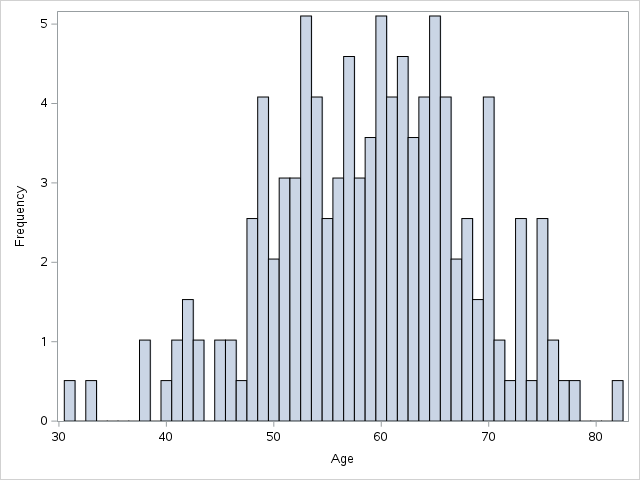

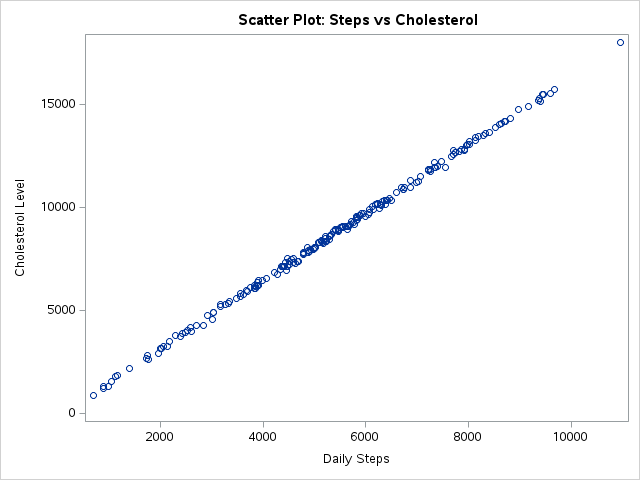

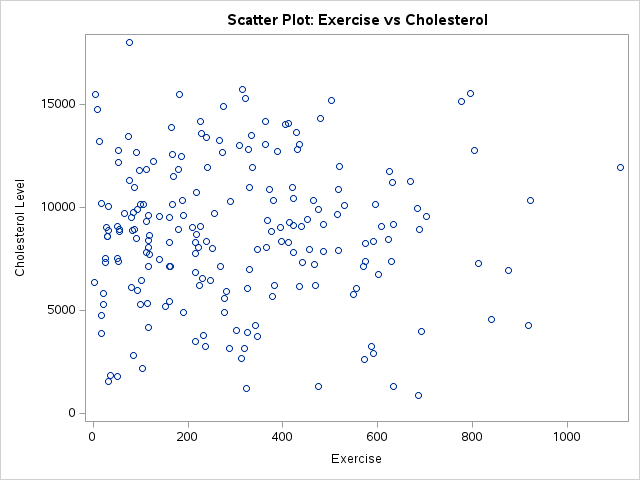

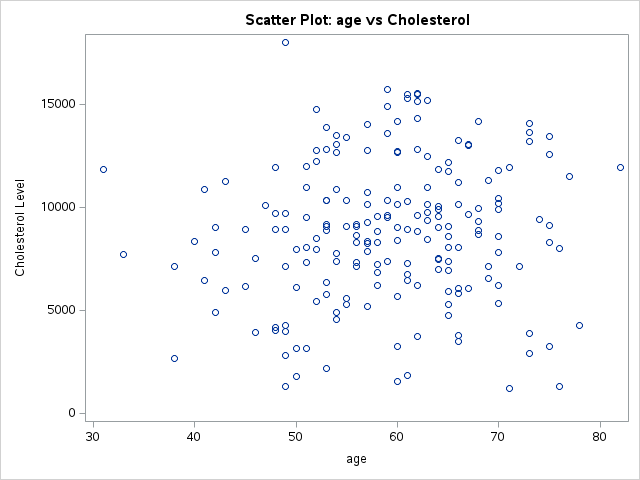

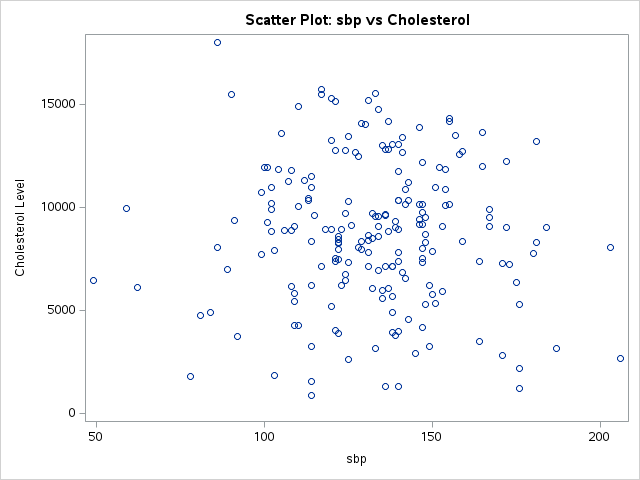

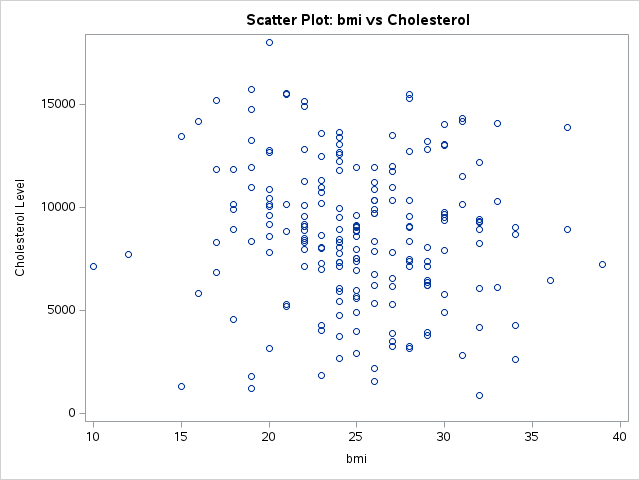

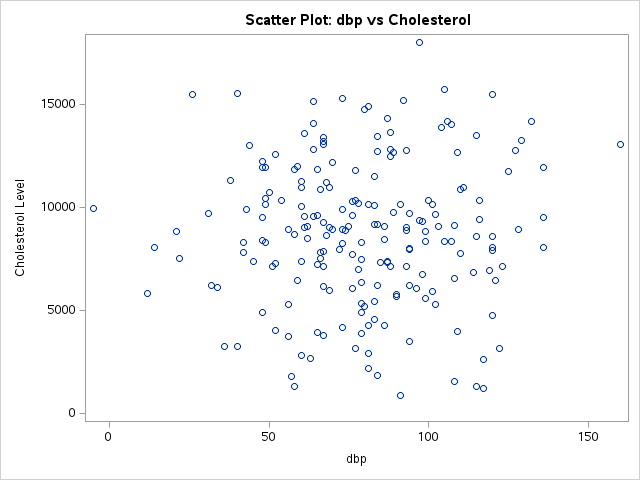

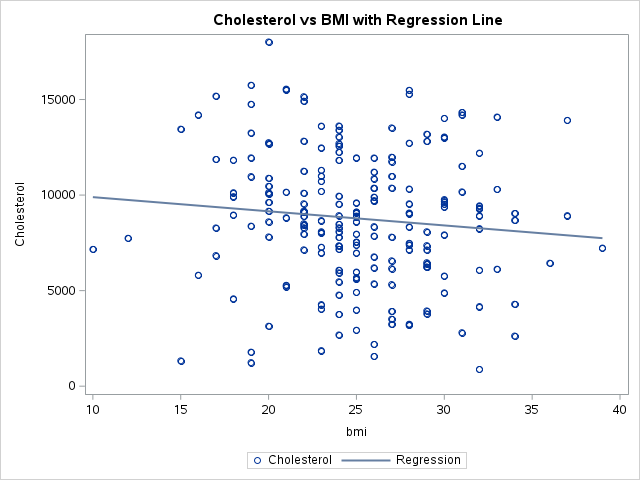

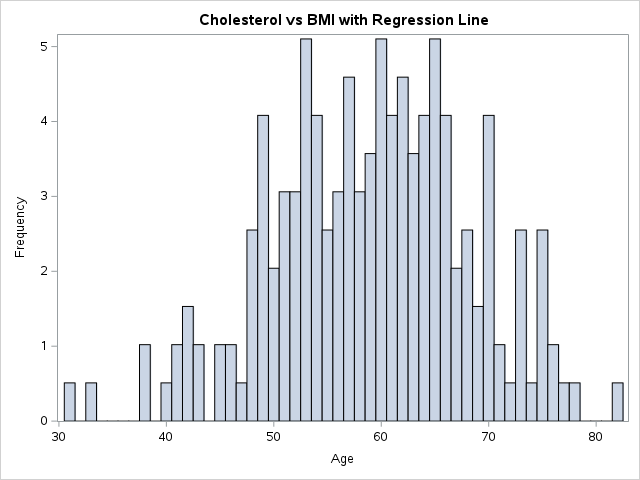

In [ ]:
proc sgplot data=SOR3004.CAD;
   histogram age / binwidth=1;
   xaxis label="Age";
   yaxis label="Frequency";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=steps y=cholesterol;
    title "Scatter Plot: Steps vs Cholesterol";
    xaxis label="Daily Steps";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=exercise y=cholesterol;
    title "Scatter Plot: Exercise vs Cholesterol";
    xaxis label="Exercise";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=age y=cholesterol;
    title "Scatter Plot: age vs Cholesterol";
    xaxis label="age";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=sbp y=cholesterol;
    title "Scatter Plot: sbp vs Cholesterol";
    xaxis label="sbp";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=bmi y=cholesterol;
    title "Scatter Plot: bmi vs Cholesterol";
    xaxis label="bmi";
    yaxis label="Cholesterol Level";
run;

proc sgplot data=SOR3004.CAD;
    scatter x=dbp y=cholesterol;
    title "Scatter Plot: dbp vs Cholesterol";
    xaxis label="dbp";
    yaxis label="Cholesterol Level";
run;


proc sgplot data=SOR3004.CAD;
    scatter x=bmi y=Cholesterol;
    reg x=bmi y=Cholesterol;
    title "Cholesterol vs BMI with Regression Line";
run;


proc sgplot data=SOR3004.CAD;
   histogram age / binwidth=1; 
   xaxis label="Age";
   yaxis label="Frequency";
run;

## Correlations

In [ ]:
proc corr data=SOR3004.CAD;
   var Cholesterol steps sbp dbp age bmi exercise takeaway;
   title "Correlation Analysis of Continuous Variables";
run;

8  Variables:  Cholesterol steps       sbp         dbp         age         bmi         exercise    takeaway


Simple Statistics
Variable       N       Mean    Std Dev        Sum    Minimum    Maximum
Cholesterol  200       8759       3478    1751851  874.68304      18014
steps        200       5406       2110    1081216  693.00000      10956
sbp          200  132.47000   24.90422      26494   49.00000  206.00000
dbp          200   79.61500   27.04596      15923   -5.00000  160.00000
age          196   59.02551    9.22563      11569   31.00000   82.00000
bmi          198   25.06566    4.78054       4963   10.00000   39.00000
exercise     200  305.49775  225.24347      61100    2.24000       1112
takeaway     199    0.66834    0.47200  133.00000          0    1.00000


Pearson Correlation Coefficients, Prob > |r| under H0: Rho=0, Number of Observations
             Cholesterol     steps       sbp      dbp       age       bmi  exercise  takeaway
Cholesterol      1.00000   0.99955  -0.04948  0.03046   0.10275  -0.10276   0.00196   0.10499
                            <.0001    0.4866   0.6685    0.1518    0.1497    0.9780    0.1400
                     200       200       200      200       196       198       200       199
steps            0.99955   1.00000  -0.04843  0.03215   0.10530  -0.10200   0.02868   0.10512
                  <.0001              0.4958   0.6513    0.1419    0.1527    0.6868    0.1395
                     200       200       200      200       196       198       200       199
sbp             -0.04948  -0.04843   1.00000  0.08692  -0.05497   0.02383   0.04353   0.09480
                  0.4866    0.4958             0.2210    0.4441    0.7390    0.5405    0.1829
                     200       200       200      200       196      

## Gender recode and frequency tables

In [ ]:
data SOR3004.CAD_cleanv1;
    set SOR3004.CAD_clean;
    length gender1 $8;
    if gender = 1 then gender1 = 'male';
    else if gender = 0 then gender1 = 'female';
    else gender1 = .;
run;

proc freq data=SOR3004.CAD_cleanv1;
   tables CAD gender1 takeaway;
run;

proc means data=SOR3004.CAD_cleanv1;
    class gender1;
    var Cholesterol;
    output out=Cholesterol_rates_gender mean=ovr_Cholesterol_mean n=count;
run;

CAD  Frequency  Percent  Cumulative Frequency  Cumulative Percent
0          102    52.04                   102               52.04
1           94    47.96                   196              100.00


gender1  Frequency  Percent  Cumulative Frequency  Cumulative Percent
female          91    46.43                    91               46.43
male           105    53.57                   196              100.00


takeaway               Frequency  Percent  Cumulative Frequency  Cumulative Percent
Frequency Missing = 1
0                             63    32.31                    63               32.31
1                            132    67.69                   195              100.00


Analysis Variable : Cholesterol
gender1  N Obs    N     Mean  Std Dev  Minimum   Maximum
female      91   91  9389.68  3343.92  1296.91  15749.55
male       105  105  8358.03  3463.67  1236.25  18013.51


## Cholesterol by gender and CAD status

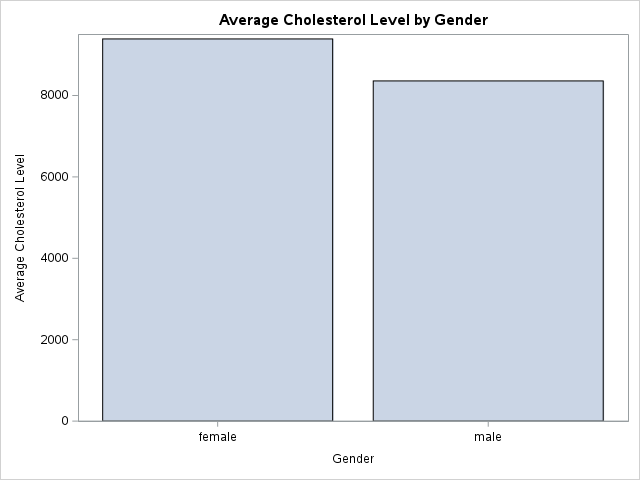

Analysis Variable : Cholesterol
CAD  N Obs    N     Mean  Std Dev  Minimum   Maximum
0      102  102  9272.99  3378.25  1236.25  18013.51
1       94   94  8363.93  3459.19  1296.91  15749.55


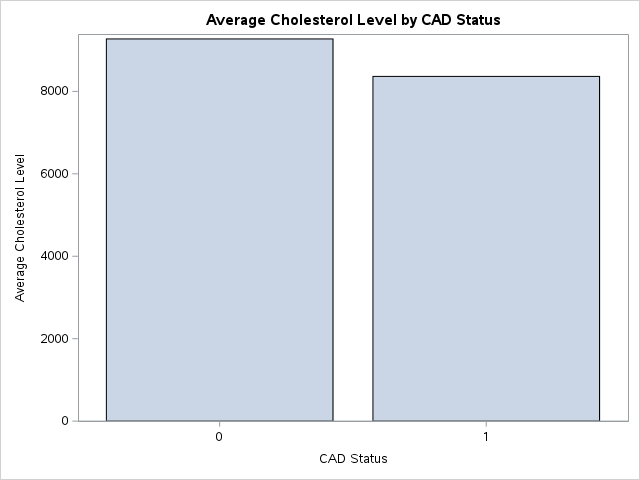

In [ ]:
proc sgplot data=Cholesterol_rates_gender;
    vbar gender1 / response=ovr_Cholesterol_mean;
    xaxis label="Gender";
    yaxis label="Average Cholesterol Level";
    title "Average Cholesterol Level by Gender"; 
run;

proc means data=SOR3004.CAD_cleanv1;
    class cad;
    var Cholesterol;
    output out=Cholesterol_rates_cad mean=ovr_Cholesterol_mean n=count;
run;

proc sgplot data=SOR3004.CAD_cleanv1;
    vbar cad / response=Cholesterol stat=mean;
    xaxis label="CAD Status";
    yaxis label="Average Cholesterol Level";
    title "Average Cholesterol Level by CAD Status";
run;

## Variable selection

Number of Observations Read                 196
Number of Observations Used                 193
Number of Observations with Missing Values    3


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              1      2223099295   2223099295   201112  <.0001
Error            191         2111322        11054
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept          -144.59924        21.48005      500937    45.32  <.0001
steps                 1.64725         0.00367  2223099295   201112  <.0001


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              2      2224784603   1112392301   496120  <.0001
Error            190          426015   2242.18374
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept           -31.96768        10.51027       20743     9.25  0.0027
steps                 1.64972         0.00166  2223182820   991526  <.0001
exercise             -0.42181         0.01539     1685307   751.64  <.0001


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              3      2224793607    741597869   336111  <.0001
Error            189          417011   2206.40530
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept            10.52238        23.47547   443.28708     0.20  0.6545
steps                 1.65001         0.00165  2206669951  1000120  <.0001
age                  -0.74790         0.37022  9004.30803     4.08  0.0448
exercise             -0.42129         0.01526     1680694   761.73  <.0001


Summary of Forward Selection
Step  Variable Entered  Number Vars In  Partial R-Square  Model R-Square     C(p)  F Value  Pr > F
1                steps               1            0.9991          0.9991  765.051   201112  <.0001
2             exercise               2            0.0008          0.9998   5.5050   751.64  <.0001
3                  age               3            0.0000          0.9998   3.4362     4.08  0.0448


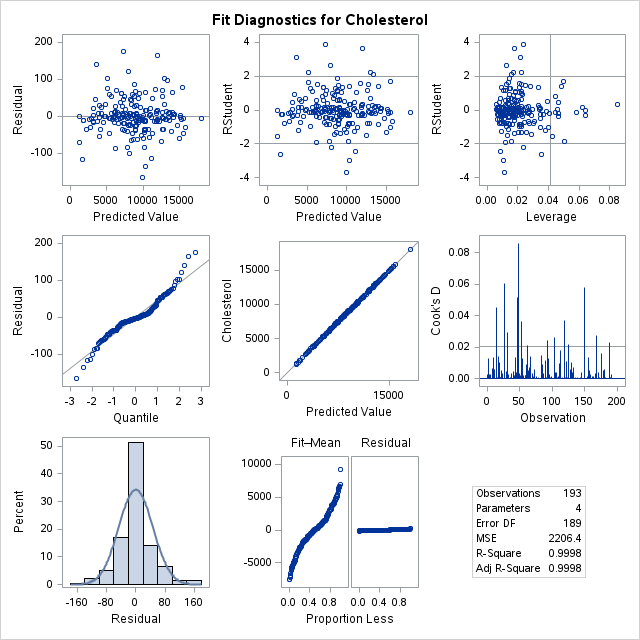

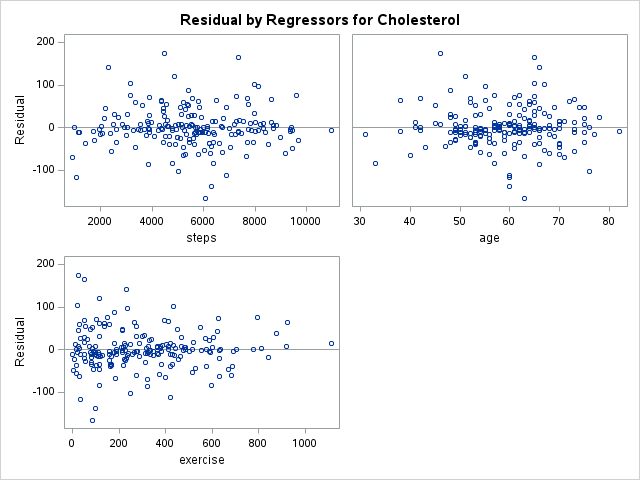

Number of Observations Read                 196
Number of Observations Used                 193
Number of Observations with Missing Values    3


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              8      2224803424    278100428   125666  <.0001
Error            184          407193   2213.00730
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept           -18.21894        36.47494   552.12801     0.25  0.6180
steps                 1.65059         0.00169  2106473208   951860  <.0001
sbp                   0.05950         0.13700   417.36907     0.19  0.6646
dbp                  -0.16436         0.12706  3702.83383     1.67  0.1975
age                  -0.70745         0.37313  7955.24370     3.59  0.0595
bmi                   1.01238         0.72337  4334.54014     1.96  0.1633
exercise             -0.42379         0.01537     1681618   759.88  <.0001
takeaway              0.73091         7.34204    21.93206     0.01  0.9208
gender                6.01639         6.91894  1673.30443     0.76  0.3857


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              7      2224803402    317829057   144391  <.0001
Error            185          407215   2201.16365
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept           -17.65821        35.94086   531.33541     0.24  0.6238
steps                 1.65060         0.00168  2119971922   963114  <.0001
sbp                   0.06083         0.13598   440.48515     0.20  0.6552
dbp                  -0.16431         0.12672  3700.93329     1.68  0.1964
age                  -0.71051         0.37087  8078.84113     3.67  0.0569
bmi                   1.00729         0.71963  4312.60917     1.96  0.1633
exercise             -0.42376         0.01533     1682027   764.15  <.0001
gender                5.97279         6.88657  1655.77412     0.75  0.3869


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              6      2224802962    370800494   169184  <.0001
Error            186          407656   2191.69763
Corrected Total  192      2225210618


... (4 outputs left out)

Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept           -14.81425        29.96975   536.73490     0.24  0.6217
steps                 1.65017         0.00165  2195572741   999495  <.0001
age                  -0.73900         0.36946  8788.45500     4.00  0.0469
bmi                   0.97145         0.71682  4034.55612     1.84  0.1770
exercise             -0.42246         0.01526     1684624   766.90  <.0001


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              3      2224793607    741597869   336111  <.0001
Error            189          417011   2206.40530
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept            10.52238        23.47547   443.28708     0.20  0.6545
steps                 1.65001         0.00165  2206669951  1000120  <.0001
age                  -0.74790         0.37022  9004.30803     4.08  0.0448
exercise             -0.42129         0.01526     1680694   761.73  <.0001


Summary of Backward Elimination
Step  Variable Removed  Number Vars In  Partial R-Square  Model R-Square    C(p)  F Value  Pr > F
1             takeaway               7            0.0000          0.9998  7.0099     0.01  0.9208
2                  sbp               6            0.0000          0.9998  5.2090     0.20  0.6552
3               gender               5            0.0000          0.9998  3.9801     0.78  0.3787
4                  dbp               4            0.0000          0.9998  3.6131     1.65  0.2004
5                  bmi               3            0.0000          0.9998  3.4362     1.84  0.1770


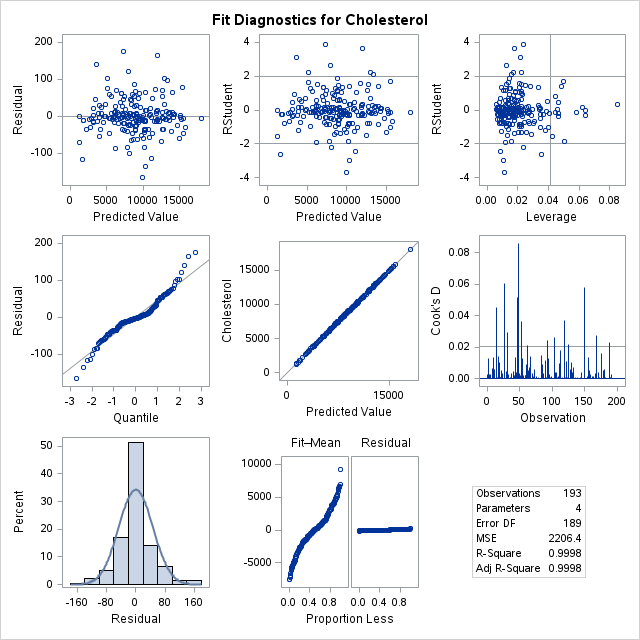

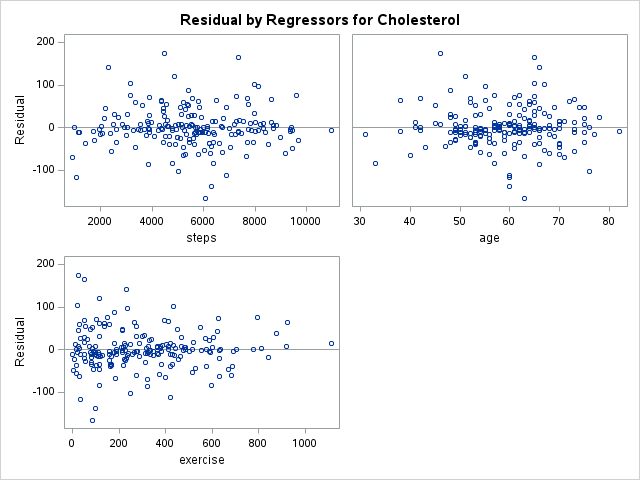

Number of Observations Read                 196
Number of Observations Used                 193
Number of Observations with Missing Values    3


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              1      2223099295   2223099295   201112  <.0001
Error            191         2111322        11054
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept          -144.59924        21.48005      500937    45.32  <.0001
steps                 1.64725         0.00367  2223099295   201112  <.0001


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              2      2224784603   1112392301   496120  <.0001
Error            190          426015   2242.18374
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept           -31.96768        10.51027       20743     9.25  0.0027
steps                 1.64972         0.00166  2223182820   991526  <.0001
exercise             -0.42181         0.01539     1685307   751.64  <.0001


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              3      2224793607    741597869   336111  <.0001
Error            189          417011   2206.40530
Corrected Total  192      2225210618


Variable   Parameter Estimate  Standard Error  Type II SS  F Value  Pr > F
Intercept            10.52238        23.47547   443.28708     0.20  0.6545
steps                 1.65001         0.00165  2206669951  1000120  <.0001
age                  -0.74790         0.37022  9004.30803     4.08  0.0448
exercise             -0.42129         0.01526     1680694   761.73  <.0001


Summary of Stepwise Selection
Step  Variable Entered  Variable Removed  Number Vars In  Partial R-Square  Model R-Square     C(p)  F Value  Pr > F
1                steps                                 1            0.9991          0.9991  765.051   201112  <.0001
2             exercise                                 2            0.0008          0.9998   5.5050   751.64  <.0001
3                  age                                 3            0.0000          0.9998   3.4362     4.08  0.0448


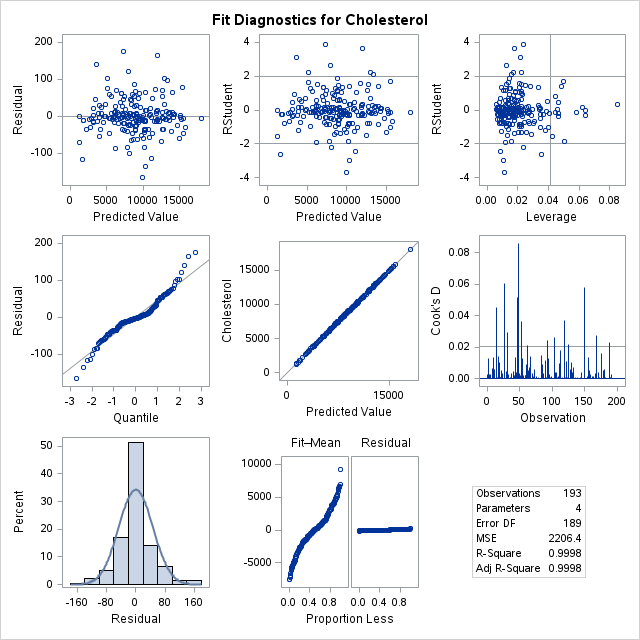

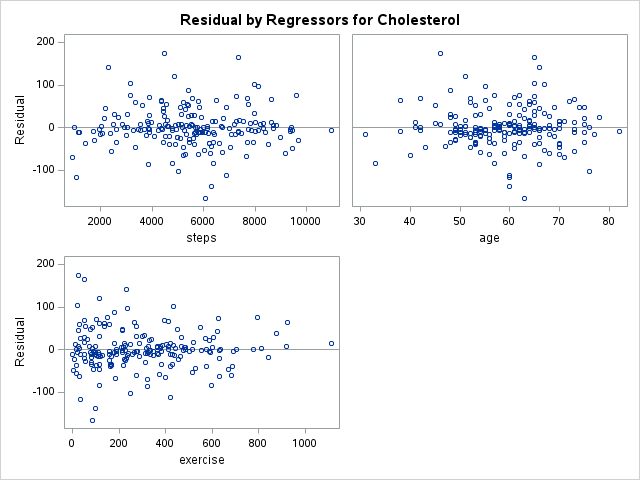

In [ ]:
/* Forward Selection*/
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / 
          selection=forward slentry=0.10;
    title "Forward Selection with All Predictors (slentry=0.10)";
run;

/* Backward Selection*/
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / 
          selection=backward slstay=0.10;
    title "Backward Selection with All Predictors (slstay=0.10)";
run;

/* Stepwise Selection*/
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / 
          selection=stepwise slentry=0.10 slstay=0.10;
    title "Stepwise Selection with All Predictors (slentry=0.10, slstay=0.10)";
run;

## Regression diagnostics

Number of Observations Read                 196
Number of Observations Used                 193
Number of Observations with Missing Values    3


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              8      2224803424    278100428   125666  <.0001
Error            184          407193   2213.00730
Corrected Total  192      2225210618


Root MSE          47.04261  R-Square  0.9998
Dependent Mean  8870.54501  Adj R-Sq  0.9998
Coeff Var          0.53032


Parameter Estimates
Variable   DF  Parameter Estimate  Standard Error  t Value  Pr > |t|
Intercept   1           -18.21894        36.47494    -0.50    0.6180
steps       1             1.65059         0.00169   975.63    <.0001
sbp         1             0.05950         0.13700     0.43    0.6646
dbp         1            -0.16436         0.12706    -1.29    0.1975
age         1            -0.70745         0.37313    -1.90    0.0595
bmi         1             1.01238         0.72337     1.40    0.1633
exercise    1            -0.42379         0.01537   -27.57    <.0001
takeaway    1             0.73091         7.34204     0.10    0.9208
gender      1             6.01639         6.91894     0.87    0.3857


Output Statistics
Obs         Residual  RStudent  Hat Diag H  Cov Ratio   DFFITS   DFBETAS
Intercept      steps       sbp         dbp        age      bmi  exercise  takeaway   gender
1           -41.9942   -0.9052      0.0283     1.0383  -0.1546    0.0559    0.0387  -0.0199   0.0409  -0.0874  -0.0337  -0.0365  -0.0498   0.0772
2            74.3017    1.6191      0.0400     0.9625   0.3303    0.0374    0.0380  -0.0805  -0.0950  -0.1319   0.1895  -0.0746   0.1007   0.1177
3             3.3208    0.0719      0.0400     1.0937   0.0147    0.0011   -0.0054   0.0004  -0.0005   0.0042  -0.0020   0.0069  -0.0075  -0.0073
4           -18.3020   -0.3968      0.0430     1.0889  -0.0841   -0.0119   -0.0489   0.0178  -0.0281   0.0073   0.0327  -0.0028  -0.0128   0.0185
5            31.4161    0.6884      0.0617     1.0935   0.1765    0.0085   -0.0886  -0.0401   0.0084   0.1032  -0.0268   0.0211  -0.0608  -0.0707
6             4.6761    0.1016      0.0475     1.1021   0.0227    0.0058    0.0007   0.

Sum of Residuals               1.45091E-10
Sum of Squared Residuals            407193
Predicted Residual SS (PRESS)       448227


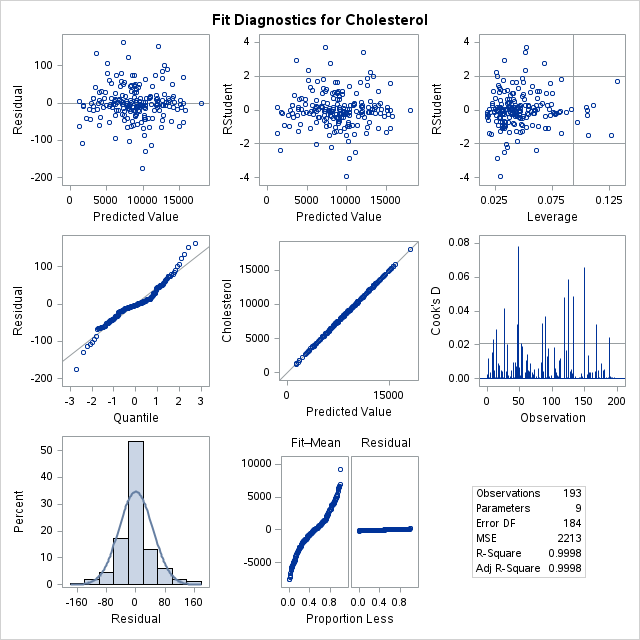

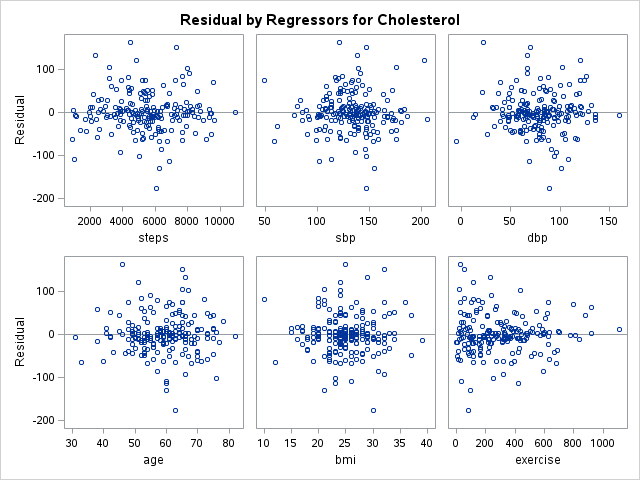

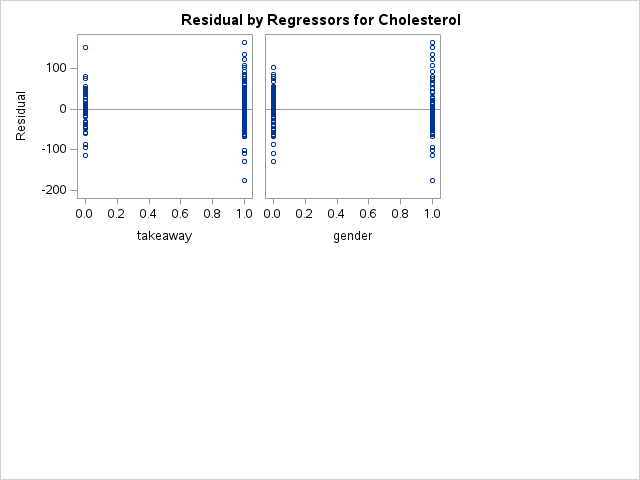

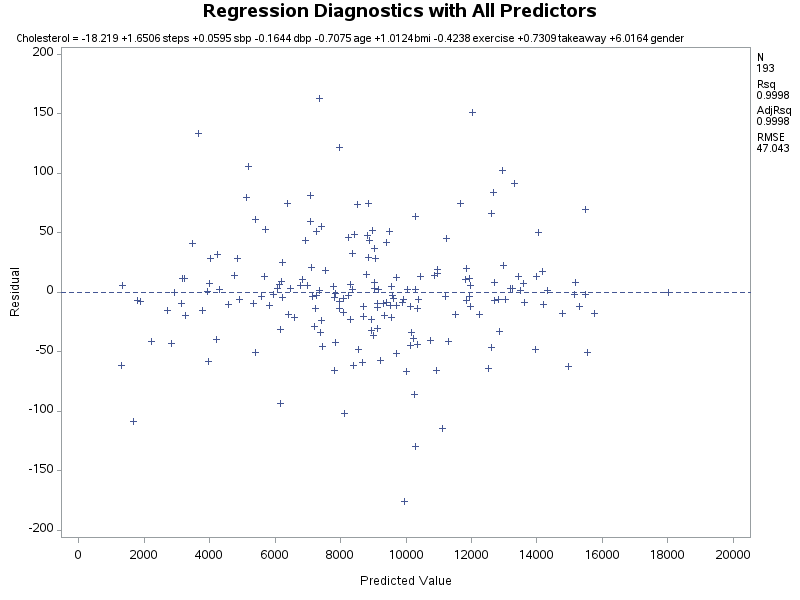

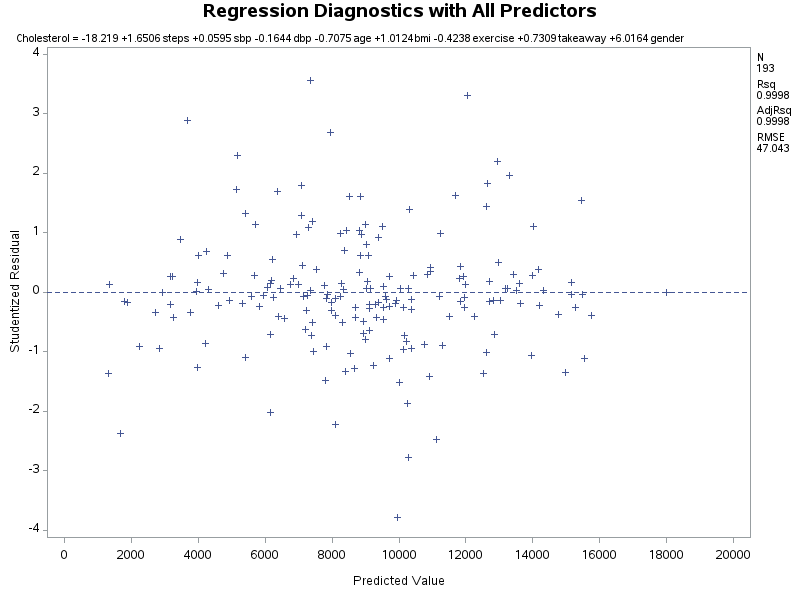

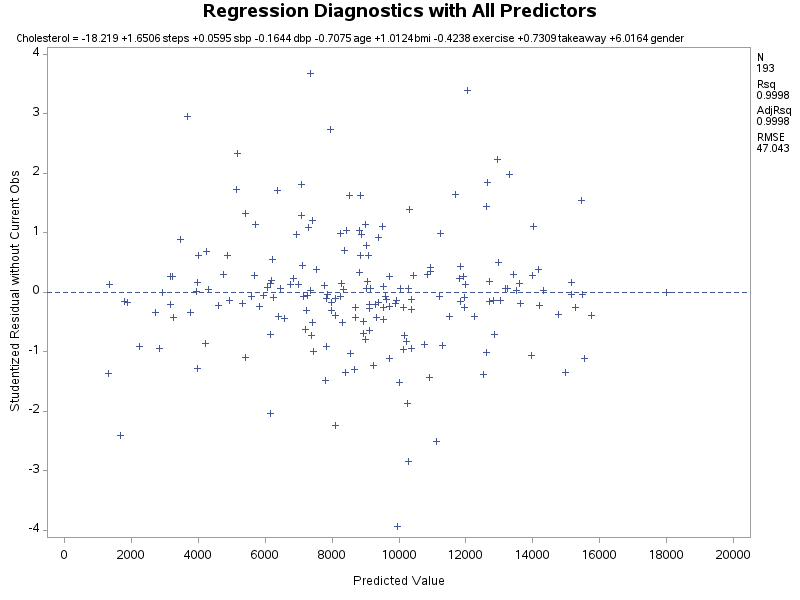

Obs  Cholesterol  steps  sbp  dbp  age  bmi  exercise  takeaway  gender  residual         r         t     cookd     press
1        7800.03   4885  140   66   70   27    422.13         1       0   -41.994  -0.90561  -0.90517  0.002658   -43.219
2        8922.13   5416  118   56   48   32    180.59         1       1    74.302   1.61199   1.61908  0.012017    77.394
3        6068.38   3845  132   76   67   24    555.66         0       0     3.321   0.07205   0.07185  0.000024     3.459
4       15749.55   9664  117  105   59   19    314.15         1       0   -18.302  -0.39769  -0.39678  0.000789   -19.123
5        4273.26   2692  109   81   78   23    341.18         0       0    31.416   0.68942   0.68843  0.003471    33.481
6        9547.91   5986  134   64   58   22    702.35         0       0     4.676   0.10185   0.10158  0.000057     4.909
7        6151.07   3847  108   67   45   27    435.57         1       1     6.412   0.13888   0.13851  0.000082     6.657
8        8601.97   5208 

In [ ]:
proc reg data=SOR3004.CAD_cleanv1;
    model Cholesterol = steps sbp dbp age bmi exercise takeaway gender / influence;
    output out=CAD_diagnostics residual=residual student=r rstudent=t 
           cookd=cookd press=press;
    plot residual.*predicted.;
    plot student.*predicted.;
    plot rstudent.*predicted.;
    plot student.*qqplot;
    title "Regression Diagnostics with All Predictors";
run;

proc print data=CAD_diagnostics;
    var Cholesterol steps sbp dbp age bmi exercise takeaway gender 
        residual r t cookd press;
    title "Diagnostic Statistics for Each Observation";
run;

## Gender and age interaction

Number of Observations Read  196
Number of Observations Used  196


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              5      2305520441    461104088   212884  <.0001
Error            190          411537   2165.98632
Corrected Total  195      2305931978


Root MSE          46.54016  R-Square  0.9998
Dependent Mean  8837.00846  Adj R-Sq  0.9998
Coeff Var          0.52665


Parameter Estimates
Variable    DF  Parameter Estimate  Standard Error  t Value  Pr > |t|
Intercept    1           -52.86279        34.03811    -1.55    0.1221
steps        1             1.65033         0.00163  1013.05    <.0001
age          1             0.21947         0.54871     0.40    0.6896
exercise     1            -0.41560         0.01491   -27.88    <.0001
gender       1           111.17145        43.65402     2.55    0.0117
gender_age   1            -1.77641         0.72994    -2.43    0.0159


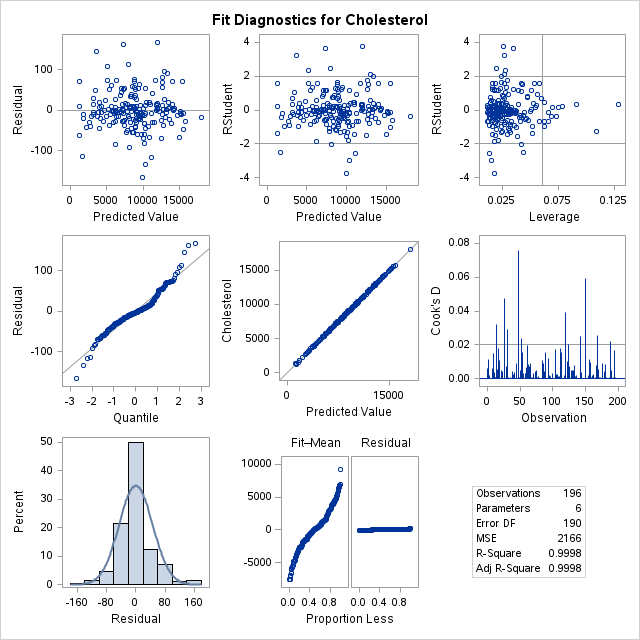

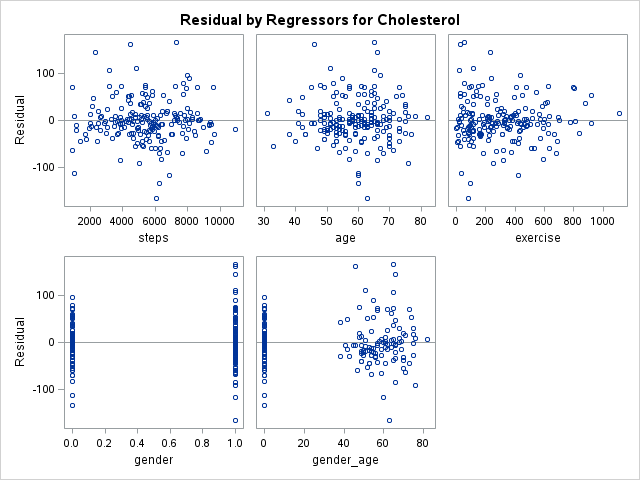

In [ ]:
data SOR3004.CAD_interaction;
    set SOR3004.CAD_cleanv1;
    gender_age = gender * age; 
run;


proc reg data=SOR3004.CAD_interaction;
    model Cholesterol = steps age exercise gender gender_age;
    title "Formal Test: Does Gender Modify Age Effect on Cholesterol?";
run;

## Box-Tidwell transformation

In [ ]:
*Box-Tidwell;
proc iml;
reset noprint;
use SOR3004.CAD_cleanv1;
read all var{age steps exercise} into x1; 
read all var{Cholesterol} into y;
int=j(nrow(x1),1,1);
alphacurrent=j(ncol(x1),1,1);    /* Now 3x1 instead of 2x1 */
x=int||x1;
firstbeta=inv(t(x)*x)*t(x)*y;
z1=x1#log(x1);
w=x1;
do i=1 to 5;
x=int||w||z1;
beta = inv(t(x)*x)*t(x)*y;
alphanew=((beta[4:6]/firstbeta[2:4])+1)#alphacurrent[1:3];
w=x1[,1]##alphanew[1]||x1[,2]##alphanew[2]||x1[,3]##alphanew[3];
x=int||w;
firstbeta = inv(t(x)*x)*t(x)*y;
z1 = w#log(w);
alphacurrent=alphanew;
print(alphacurrent);
end;
quit;

alphacurrent
1.8921688
0.2170324
1.0092944


## Transformed regression

Number of Observations Read  196
Number of Observations Used  196


Analysis of Variance
Source            DF  Sum of Squares  Mean Square  F Value  Pr > F
Model              3      2171863039    723954346  1036.77  <.0001
Error            192       134068940       698276
Corrected Total  195      2305931978


Root MSE         835.62894  R-Square  0.9419
Dependent Mean  8837.00846  Adj R-Sq  0.9410
Coeff Var          9.45602


Parameter Estimates
Variable     DF  Parameter Estimate  Standard Error  t Value  Pr > |t|
Intercept     1              -25154       633.30092   -39.72    <.0001
newsteps      1          5319.49033        95.88131    55.48    <.0001
newexercise   1            -0.30792         0.25116    -1.23    0.2217
newage        1             0.09126         0.09165     1.00    0.3206


Output Statistics
Obs         Residual     RStudent  Hat Diag H  Cov Ratio   DFFITS  DFBETAS
Intercept   newsteps  newexercise      newage
1          -791.9880      -0.9545      0.0145     1.0166  -0.1157   0.0123   0.0145  -0.0361  -0.0852
2          -365.5520      -0.4396      0.0140     1.0314  -0.0524  -0.0094  -0.0085   0.0170   0.0376
3          -756.3212      -0.9129      0.0180     1.0219  -0.1235  -0.0233   0.0479  -0.0763  -0.0589
4               1839       2.2427      0.0172     0.9364   0.2967  -0.2133   0.2484  -0.0051  -0.0313
5          -333.8263      -0.4077      0.0441     1.0645  -0.0875  -0.0213   0.0448  -0.0065  -0.0721
6          -382.5229      -0.4620      0.0222     1.0396  -0.0695   0.0110  -0.0096  -0.0593   0.0078
7          -579.0581      -0.6988      0.0191     1.0305  -0.0976  -0.0494   0.0261  -0.0327   0.0713
8          -550.9709      -0.6633      0.0146     1.0268  -0.0808   0.0016  -0.0037   0.0582  -0.0300
9          -525.0228      -0.6297      0.0074

Sum of Residuals                       0
Sum of Squared Residuals       134068940
Predicted Residual SS (PRESS)  144516322


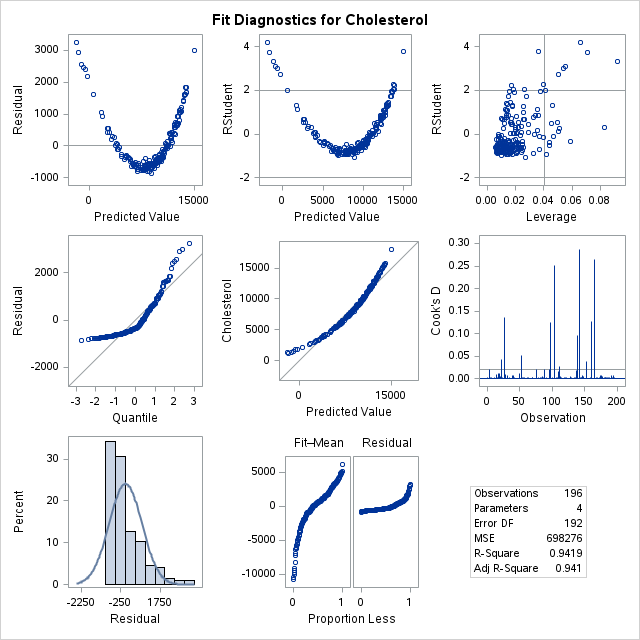

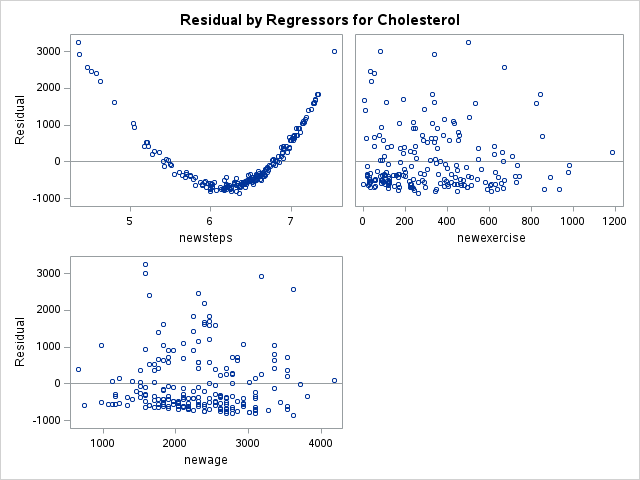

In [ ]:
data SOR3004.CAD_transformed;
set SOR3004.CAD_cleanv1; 
newsteps = steps**0.217;
newexercise = exercise**1.009;
newage = age**1.892;
run;

proc reg data=SOR3004.CAD_transformed;
model Cholesterol = newsteps newexercise newage / influence;
plot rstudent * predicted.;
run;

## Principal components and VIF

In [ ]:
proc princomp data=SOR3004.CAD_cleanv1;
var newsteps newage newexercise;
run;

*VIF and colinearity;
proc reg data=SOR3004.CAD_cleanv1;
model Cholesterol = newsteps newage newexercise / vif collinoint corrb;
run;

The exported results contain no output for these two steps. They refer to the transformed variables (newsteps, newexercise, newage), which are created in a different dataset from the one they read.